# Task 8 · Initial dashboard

Iteration 6 · Implementation and delivery. Notebook documenting the task as required by `AGENTS.md` §4.
It covers the whole run: the throwaway prototype, the design choices written into `DESIGN.md` and the dashboard built in the pipeline.

## 1. Prompt

First prompt:

> can we do a run and get an initial dashboard?

The agent ran the pipeline and asked how to proceed, because `DESIGN.md` was empty and the dashboard belongs to Iteration 6. Question and answer:

> DESIGN.md doesn't define the dashboard yet: number and date formats, chart style, which charts go on each of the 2 screens, and filters are all empty. In the plan the dashboard is also Iteration 6, after the data exploration. How do you want to get an initial dashboard?
>
> **Answer:** Throwaway prototype (Recommended)

After seeing the prototype, the person wrote:

> write these choices into DESIGN.md, build the dashboard in iteration 6 and rewrite the bitacora from this run

## 2. Task and scope

**Task (TASKS.md, Iteration 6), added in this run at the person's request:**

> 8. Initial dashboard: `uv run python -m src.pipeline` writes `dashboard/data/*.json` and a 2-screen `dashboard/index.html` following DESIGN.md §1–§5 (R10, R11, R12, R13; CA1, CA2)

**Requirements (SPECS.md §5):**

- **R10.** Every run of the pipeline regenerates `dashboard/index.html` and all files in `dashboard/data/`. No dashboard file is edited by hand.
- **R11.** Charts reference their data by URL (`alt.UrlData`) to the JSON files; the JSON files contain pre-aggregated data, never the raw rows.
- **R12.** The dashboard shows the data source and the date of the most recent accident.
- **R13.** The figures in the JSON files are consistent with `accidents.parquet`.

**Acceptance criteria with a test:** CA1 (files regenerated), CA2 (data by URL, aggregated). CA3 and CA4 have no test yet (section 7).

**Out of scope:** data cleaning and the exploration tasks 2–7 (Iteration 1), filters, dark mode, editing `SPECS.md`, `ARCHITECTURE.md` or `tests/acceptance/`.

**Order of work:** the person asked for the dashboard before tasks 2–7 and Iterations 2–5. The dashboard therefore uses the uncleaned data of task 1.

## 3. Principles and best practices applied

| Principle | Where | Why |
| --- | --- | --- |
| Prototype before committing to a design | Throwaway prototype in a scratch folder, outside the repository | `AGENTS.md` §1: do not assume what `DESIGN.md` does not say; the person chose the design from something visible |
| Specification before code | `DESIGN.md` §1–§5 written before `src/dashboard*.py` | `DESIGN.md` is the reference for how it looks (`AGENTS.md` §1) |
| Separation of responsibilities | `src/dashboard_data.py` only aggregates, `src/dashboard.py` only draws and writes the page, `src/pipeline.py` only connects the steps | Small modules that can be tested on their own (`AGENTS.md` §6, `ARCHITECTURE.md` §3) |
| Small pure functions | One function per table and per chart; none modifies its input | `AGENTS.md` §6, no hidden side effects |
| No hard-coded results | Chart titles and KPI figures are computed from the tables on every run; the neighbourhood average is computed by Vega from the JSON | `AGENTS.md` §5; R10 (regenerated every run) |
| Data by URL, aggregated | `alt.UrlData("data/<name>.json")` for every chart; no axis or rule with inline values | R11, CA2 |
| Formats defined once | `format_number`, `format_change` and the Vega `formatLocale` follow `DESIGN.md` §2 | Same figures look the same in tiles, titles, axes and tooltips |
| Honest representation | Counts start at zero; one axis per chart; footnote with the 232 accidents without a district and the unanswered P4 | `DESIGN.md` §3 and "Represent the data honestly" |
| Test-first for edge cases | Division by zero in the KPI change found by a unit test warning, then specified in `DESIGN.md` §2 and fixed | `AGENTS.md` §3.3 |
| Logic in `src/`, notebook only calls it | Section 6 imports from `src/` | `ARCHITECTURE.md` §2 |

## 4. Reasoning and decisions

**How to get an initial dashboard** (asked to the person, section 1). Options offered: a throwaway prototype, drafting `DESIGN.md` first, or building directly in the pipeline with the agent's defaults. *Chosen by the person:* the throwaway prototype.

**Prototype (scratch folder, not in the repository).** One script read `accidents.parquet`, aggregated it and wrote a 2-screen page with the charts' data inline, so that it opened from `file://`. Corrections made while building it:

- Two titles claimed more than the figures showed and were rewritten: "Weekday afternoons concentrate most accidents" → peak computed from the data (Fridays at 14 h); "15 neighbourhoods are far above the city average" → ratio of the top neighbourhood to the average (7×).
- The deaths tile showed "▼ 0.0%" when the value did not change; it now shows "= same as 2024".

**From prototype to pipeline.**

- *Inline data → JSON by URL (R11).* The neighbourhood average, a separate inline table in the prototype, is now computed by Vega (`joinaggregate`) from `serious_by_neighbourhood.json`, which holds all 74 neighbourhoods; the chart keeps the top 15 with a `row_number` window.
- *Axis ticks every 3 hours.* An explicit list of tick values would put a `"values"` key in the page, which CA2 forbids; a `labelExpr` hides the other labels instead.
- *Fixed titles → computed titles.* The prototype's titles were written for this data; in the pipeline every title is computed (lowest year, peak hour, top district, ratio to the average, whether serious accidents rose every year, top pedestrian cause), so it stays true when the data changes.
- *Number format.* The prototype mixed "7 741" in tiles with "10,000" on axes. `DESIGN.md` §2 now fixes a space as thousands separator everywhere, applied to Vega through `formatLocale`.
- *Where the dashboard is built.* `run()` (task 1, unit-tested on a temporary file) was left unchanged; a new `main()` runs it and then `build_dashboard`, so the unit test of `run()` does not overwrite the real dashboard.
- *Previous value 0.* A unit test produced a division-by-zero warning in the KPI change. Decision recorded in `DESIGN.md` §2: no percentage, the tile shows "was 0 in <year>".

**Assumptions (not confirmed by the person):**

- The data source text "Open Data BCN, Guàrdia Urbana accident files" is inferred from the file names (`*_accidents_gu_bcn.csv`).
- Labels in English with place names in Catalan; a space as thousands separator and a point as decimal separator. These come from the prototype, which the person approved as a whole.

**Not done in this run:** dark mode (`DESIGN.md` §3 says light only for now) and filters (`DESIGN.md` §5).

## 5. Changes to the source code

| archivo | tipo de cambio | motivo | R/CA |
| --- | --- | --- | --- |
| `DESIGN.md` | modified (§1–§5 written, by the person's instruction) | Naming, formats, chart style, structure and data files of the dashboard | R10–R13 |
| `src/dashboard_data.py` | created | Six aggregated tables and their JSON files | R11, R13 / CA2 |
| `src/dashboard.py` | created | Altair charts by URL, KPI tiles, header with source and latest date, page | R10, R11, R12 / CA1, CA2 |
| `src/pipeline.py` | modified | New `main()`: Parquet, then the dashboard | R10 / CA1 |
| `tests/unit/test_dashboard_data.py` | created | Tables on a 5-accident example calculated by hand | R11, R13 |
| `tests/unit/test_dashboard_page.py` | created | Formats and a whole build on a 3-accident example | R10, R11, R12 |
| `TASKS.md` | modified | Task 8 added in Iteration 6, marked `[x]` with the `Agente:` line | — |
| `notebooks/bitacora/2026-11-26_T8_initial_dashboard.ipynb` and `img/` | created | This notebook and two screenshots | — |
| `dashboard/index.html`, `dashboard/data/*.json` | generated | Output of the pipeline (not edited by hand, R10) | R10 |

**`src/pipeline.py`, new entry point:**

```python
def main() -> None:
    """Full pipeline: accidents.parquet, then the dashboard regenerated from it (R1, R2, R10)."""
    run()
    build_dashboard(pd.read_parquet(ACCIDENTS_PARQUET), DASHBOARD_DIR)
```

**`src/dashboard_data.py`, one table and the edge case of the KPI change:**

```python
def accidents_per_year(accidents: pd.DataFrame) -> pd.DataFrame:
    """Accidents, serious or fatal accidents, victims and deaths per year (R13; DESIGN.md §4)."""
    table = accidents.assign(serious=is_serious(accidents))
    return (table.groupby("nk_any")
            .agg(accidents=("numero_expedient", "size"), serious=("serious", "sum"),
                 victims=("numero_victimes", "sum"), deaths=("numero_morts", "sum"))
            .rename_axis("year").reset_index()
            .astype("int64"))


def change_pct(value: float, previous_value: float) -> float | None:
    """Change from the previous value in %; None when the previous value is 0 (DESIGN.md §2)."""
    if previous_value == 0:
        return None
    return (value - previous_value) / previous_value * 100
```

**`src/dashboard.py`, a chart loading its data by URL with a title computed from the data:**

```python
def chart_weekday_hour(by_weekday_hour: pd.DataFrame, period: str) -> alt.Chart:
    """Heatmap of accidents by weekday and hour; the title names the peak (P2; DESIGN.md §4)."""
    peak = by_weekday_hour.loc[by_weekday_hour["accidents"].idxmax()]
    title = f"Accidents peak on {WEEKDAY_NAMES[peak['weekday']]} at {peak['hour']} h"
    return alt.Chart(_url("accidents_by_weekday_hour")).mark_rect(cornerRadius=2).encode(
        x=alt.X("hour:O", title="Hour of day",
                axis=alt.Axis(labelAngle=0, labelExpr="datum.value % 3 == 0 ? datum.label : ''")),
        y=alt.Y("weekday:O", title=None, sort=WEEKDAY_ORDER),
        ...
```

## 6. Verification

Commands run from the repository root, with their actual output.

**`uv run python -m src.pipeline`**: exit code 0; wrote `data/processed/accidents.parquet`, `dashboard/index.html` and six files in `dashboard/data/`. A check of the page found no `"values"` key and these chart URLs:

```
      1 "url": "data/accidents_by_weekday_hour.json"
      2 "url": "data/accidents_per_year.json"
      1 "url": "data/pedestrian_causes.json"
      1 "url": "data/serious_by_district.json"
      1 "url": "data/serious_by_neighbourhood.json"
```

**First run of the unit tests**, before handling a previous value of 0 (34 passed, 3 warnings):

```
c:\template\src\dashboard_data.py:40: RuntimeWarning: divide by zero encountered in scalar divide
  "change_pct": (last[column] - previous[column]) / previous[column] * 100}
34 passed, 3 warnings in 3.02s
```

**After the fix, `uv run pytest tests/unit tests/acceptance/test_data.py tests/acceptance/test_dashboard.py -q`** (tests applicable to this task):

```
..................................                                       [100%]
34 passed in 3.84s
```

**`uv run pytest -q`** (whole suite). The 6 errors are the exploration tests, which need `src/exploration.py` (tasks 2–6):

```
ERROR tests/acceptance/test_exploration.py::test_profile_fields - ModuleNotFo...
ERROR tests/acceptance/test_exploration.py::test_check_derived_columns - Modu...
ERROR tests/acceptance/test_exploration.py::test_check_identity_and_coverage
ERROR tests/acceptance/test_exploration.py::test_check_geography - ModuleNotF...
ERROR tests/acceptance/test_exploration.py::test_count_by - ModuleNotFoundErr...
ERROR tests/acceptance/test_exploration.py::test_describe_counts - ModuleNotF...
34 passed, 6 errors in 4.31s
```

**`uv run python scripts/traceability.py`**: exit code 1, only because CA3 and CA4 have no test.

```
✔ CA1: tests\acceptance\test_dashboard.py
✔ CA2: tests\acceptance\test_dashboard.py
✘ CA3: NO TEST
✘ CA4: NO TEST
✔ CA5 … CA12 (test_data.py, test_exploration.py)

2 criterion/criteria without a test and 0 unknown reference(s).
```

**Visual check.** The page loads its JSON by URL, which browsers block from `file://`, so it was served with `uv run python -m http.server 8765 -d dashboard` and captured with a headless browser at 1440 × 900. Both screens fit without scrolling and no labels overlap (screenshots at the end of this section).

**Demonstration on the real data.** The cells below rebuild the dashboard from `src/` and show its tables.

In [1]:
import sys
from pathlib import Path

# Make the repository root importable, wherever the notebook is opened from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src.dashboard import format_change, format_number
from src.pipeline import ACCIDENTS_PARQUET, DASHBOARD_DIR, main

In [2]:
main()  # full pipeline: Parquet, then dashboard (R10)
accidents = pd.read_parquet(ACCIDENTS_PARQUET)
written = sorted(p.relative_to(ROOT).as_posix() for p in [DASHBOARD_DIR / "index.html", *(DASHBOARD_DIR / "data").glob("*.json")])
print("\n".join(written))

dashboard/data/accidents_by_weekday_hour.json
dashboard/data/accidents_per_year.json
dashboard/data/kpis.json
dashboard/data/pedestrian_causes.json
dashboard/data/serious_by_district.json
dashboard/data/serious_by_neighbourhood.json
dashboard/index.html


In [3]:
# KPI tiles as shown on screen (DESIGN.md §2).
kpis = pd.read_json(DASHBOARD_DIR / "data" / "kpis.json")
kpis.assign(shown=[f"{format_number(v)} · {format_change(c, p)}"
                   for v, c, p in zip(kpis["value"], kpis["change_pct"], kpis["previous_year"])])

,indicator,year,value,previous_year,previous_value,change_pct,shown
0,Accidents,2025,7741,2024,7536,2.720276,7 741 · ▲ 2.7% vs 2024
1,Victims,2025,8636,2024,8511,1.468688,8 636 · ▲ 1.5% vs 2024
2,Serious or fatal accidents,2025,252,2024,249,1.204819,252 · ▲ 1.2% vs 2024
3,Deaths,2025,11,2024,11,0.000000,11 · = same as 2024


In [4]:
# R13: the accidents per year add up to the rows of accidents.parquet.
per_year = pd.read_json(DASHBOARD_DIR / "data" / "accidents_per_year.json")
print("Sum of accidents per year:", per_year["accidents"].sum(), "| rows in accidents.parquet:", len(accidents))
per_year

Sum of accidents per year: 54954 | rows in accidents.parquet: 54954


,year,accidents,serious,victims,deaths
0,2019,10027,207,11864,22
1,2020,6268,140,7230,14
2,2021,7659,164,8872,12
3,2022,7999,193,9093,24
4,2023,7724,233,8801,21
5,2024,7536,249,8511,11
6,2025,7741,252,8636,11


In [5]:
# R11: every JSON table is aggregated (far fewer rows than accidents.parquet).
pd.DataFrame({name.stem: [len(pd.read_json(name))] for name in sorted((DASHBOARD_DIR / "data").glob("*.json"))},
             index=["rows"]).T

,rows
accidents_by_weekday_hour,168
accidents_per_year,7
kpis,4
pedestrian_causes,5
serious_by_district,10
serious_by_neighbourhood,74


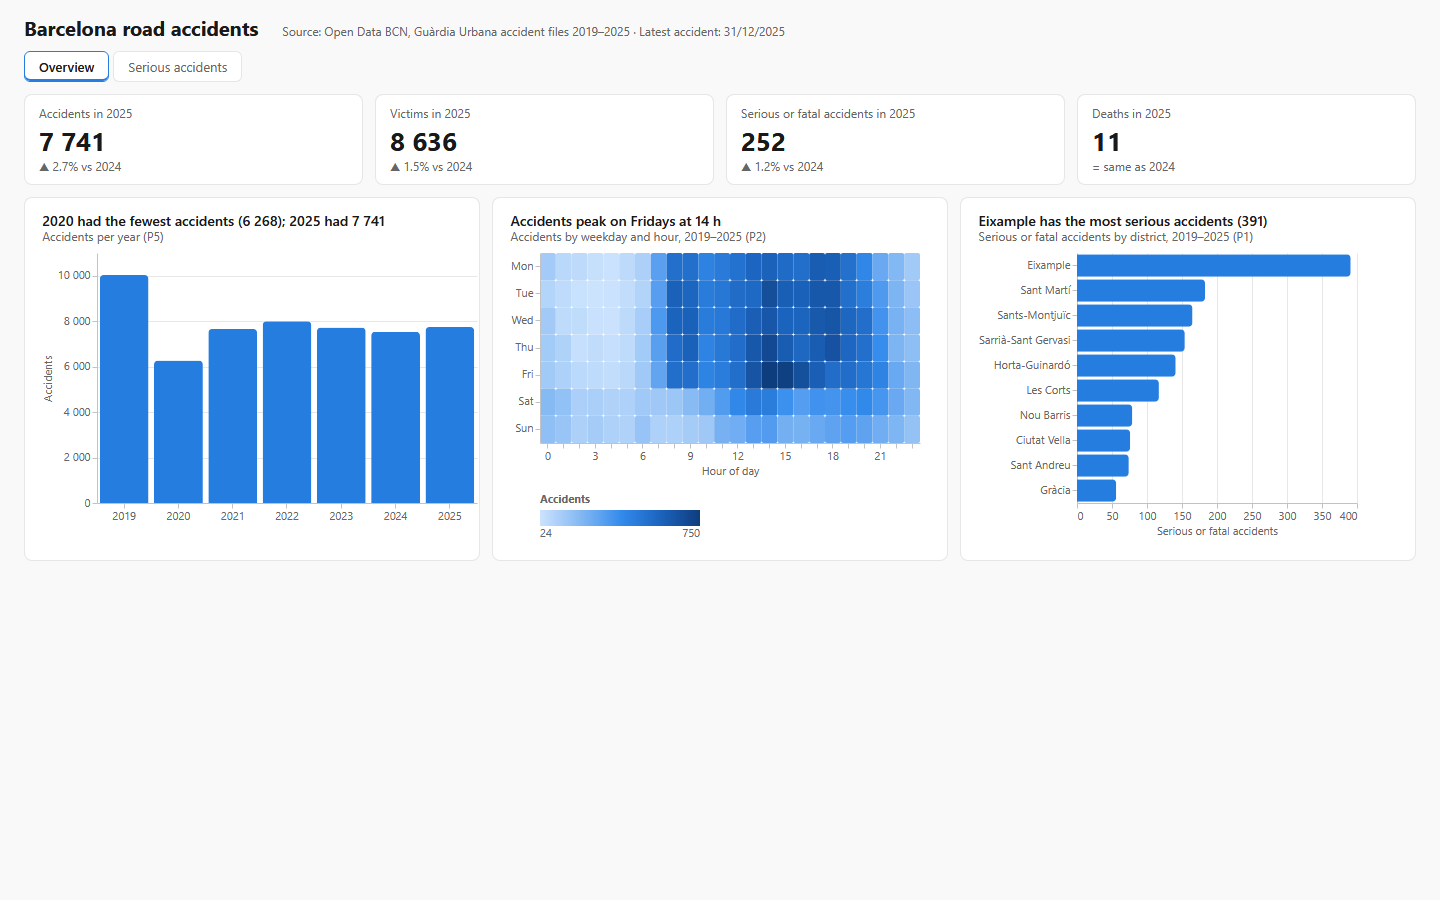

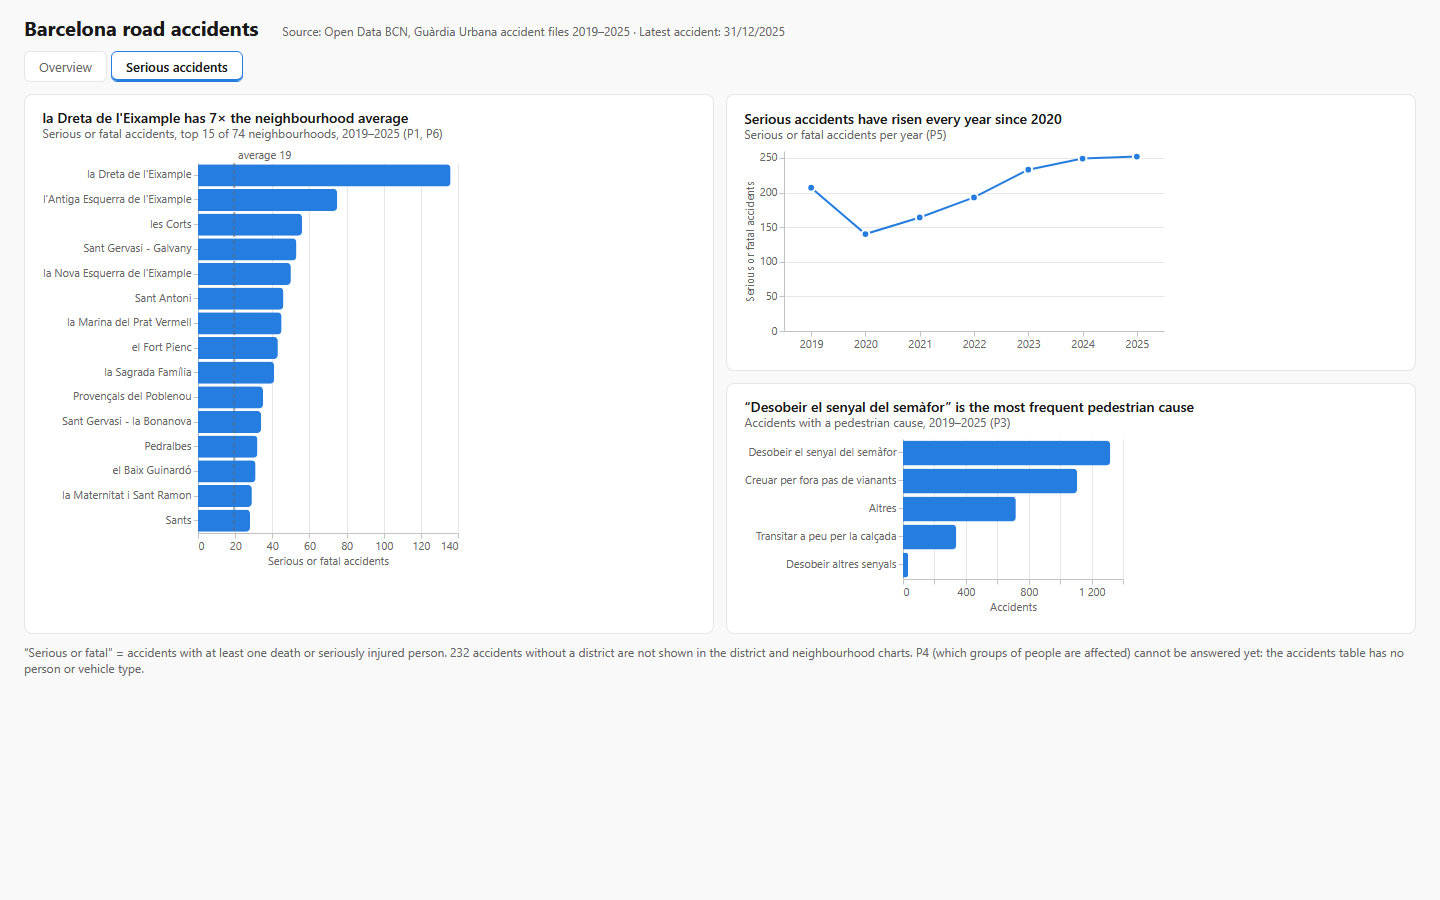

In [6]:
display(Image(filename="img/2026-11-26_T8_overview.png", width=900))
display(Image(filename="img/2026-11-26_T8_detail.png", width=900))

## 7. Pending issues

**Tests deferred (not failures of this task):**

- CA3 and CA4 have no test. `DESIGN.md` now gives what they need: the date format (dd/mm/yyyy, §2) and the table whose total must match (`accidents_per_year.json`, `accidents` column, §4). The team can make CA4's `<summary table>` concrete in `SPECS.md` §6 and write both tests.
- `tests/acceptance/test_exploration.py` (CA8–CA12) waits for tasks 2–6.

**Noticed outside the scope of this task (reported, not fixed):**

- The dashboard uses the uncleaned data of task 1; tasks 2–7 may change figures (e.g. the two spellings of `No és causa del vianant`, the 232 accidents without a district).
- Viewing the dashboard needs a local server (`uv run python -m http.server -d dashboard`, then open `http://localhost:8000`); this command is not yet in the `AGENTS.md` §2 table or the README.
- `ARCHITECTURE.md` §1, §3 and §4 are still empty; §3 lists `app.py`, which does not exist, and not `dashboard_data.py` or `dashboard.py`.
- The data source text on the dashboard is an assumption to be confirmed (section 4).
- `dashboard/` is not in `.gitignore`: the team should decide whether the generated dashboard is committed.
- SPECS.md §2 (users and questions) is empty; P1–P6 are only in TASKS.md, Iteration 2.
- P4 (groups of people affected) cannot be answered with the current table.